In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt



The last two digits of my ID are **28**, so d = 28.

In [2]:
d = 28
print("My d =", d)

My d = 28


In [3]:
c_obs      = 20 + d
cpp_obs    = 25 + (d % 10)
java_obs   = 30 + (d % 7)
python_obs = 35 + (d % 5)

print("C      =", c_obs)
print("C++    =", cpp_obs)
print("Java   =", java_obs)
print("Python =", python_obs)

C      = 48
C++    = 33
Java   = 30
Python = 38


In [4]:
languages = ["C", "C++", "Java", "Python"]
observed = np.array([c_obs, cpp_obs, java_obs, python_obs])

print("Languages:", languages)
print("Observed :", observed)
print("Total students (n) =", observed.sum())

Languages: ['C', 'C++', 'Java', 'Python']
Observed : [48 33 30 38]
Total students (n) = 149


In [5]:
alpha = 0.05
print("Significance level (alpha) =", alpha)

Significance level (alpha) = 0.05


In [6]:
total = observed.sum()
k = len(observed)          # number of categories = 4

expected_each = total / k
expected = np.array([expected_each] * k)

print("Expected frequencies:", expected)

Expected frequencies: [37.25 37.25 37.25 37.25]


In [7]:
diff = observed - expected
print("O - E          :", diff)

diff_squared = diff ** 2
print("(O - E)^2      :", diff_squared)

each_part = diff_squared / expected
print("(O - E)^2 / E  :", np.round(each_part, 4))

O - E          : [10.75 -4.25 -7.25  0.75]
(O - E)^2      : [115.5625  18.0625  52.5625   0.5625]
(O - E)^2 / E  : [3.1023 0.4849 1.4111 0.0151]


In [8]:
chi_square = each_part.sum()
print("Chi-square statistic =", round(chi_square, 4))

Chi-square statistic = 5.0134


In [9]:
df = k - 1
print("Degrees of freedom =", df)

Degrees of freedom = 3


In [10]:
critical_value = stats.chi2.ppf(1 - alpha, df)
print("Critical value =", round(critical_value, 4))

Critical value = 7.8147


In [11]:
p_value = 1 - stats.chi2.cdf(chi_square, df)
print("p-value =", round(p_value, 4))

p-value = 0.1708


In [12]:
test_stat, test_p = stats.chisquare(f_obs=observed, f_exp=expected)

print("My chi-square    :", round(chi_square, 4))
print("SciPy chi-square :", round(test_stat, 4))
print("My p-value       :", round(p_value, 4))
print("SciPy p-value    :", round(test_p, 4))

My chi-square    : 5.0134
SciPy chi-square : 5.0134
My p-value       : 0.1708
SciPy p-value    : 0.1708


In [13]:
print("Chi-square     =", round(chi_square, 4))
print("Critical value =", round(critical_value, 4))
print("p-value        =", round(p_value, 4))
print()

if chi_square > critical_value:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Chi-square     = 5.0134
Critical value = 7.8147
p-value        = 0.1708

Decision: Fail to reject H0


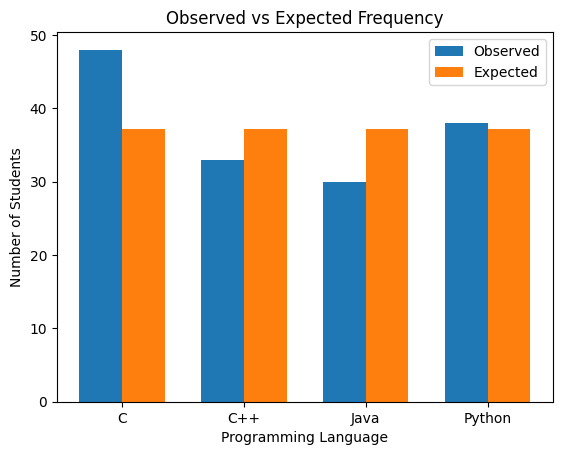

In [14]:
x = np.arange(len(languages))
width = 0.35

plt.bar(x - width/2, observed, width, label="Observed")
plt.bar(x + width/2, expected, width, label="Expected")

plt.xticks(x, languages)
plt.xlabel("Programming Language")
plt.ylabel("Number of Students")
plt.title("Observed vs Expected Frequency")
plt.legend()
plt.show()

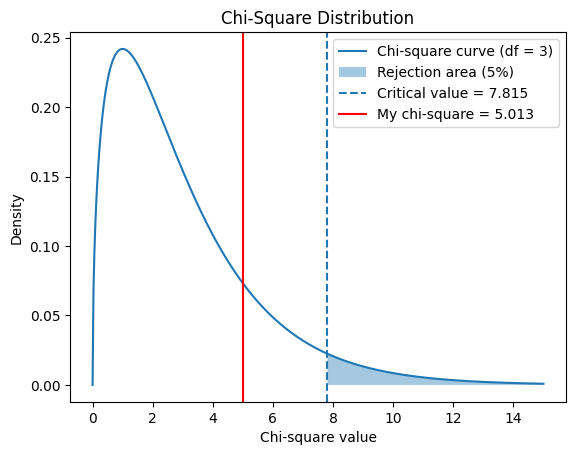

In [15]:
xs = np.linspace(0, 15, 500)
ys = stats.chi2.pdf(xs, df)

plt.plot(xs, ys, label="Chi-square curve (df = 3)")

# shade the rejection area
xs_reject = np.linspace(critical_value, 15, 200)
plt.fill_between(xs_reject, stats.chi2.pdf(xs_reject, df), alpha=0.4, label="Rejection area (5%)")

plt.axvline(critical_value, linestyle="--", label="Critical value = " + str(round(critical_value, 3)))
plt.axvline(chi_square, color="red", label="My chi-square = " + str(round(chi_square, 3)))

plt.xlabel("Chi-square value")
plt.ylabel("Density")
plt.title("Chi-Square Distribution")
plt.legend()
plt.show()